# CA2, Phase 1: DCF and the slotted contention model

This notebook is **optional**: any language or tool is fine for the analysis (see the setup section of the assignment). It only **loads** simulation results; the model, the plots and the analysis are yours to write, in new cells under each section heading.

Rules:
- Your group's parameters come from `../params.json` (written by `ca2_params.py`). Do not type L or R by hand.
- Every number and plot in your report must be reproducible from the code you hand in; the TAs do not run it, but at the in-person delivery you will rerun parts of it and change them.

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from omnetpp.scave import results

with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)
L, R = P["L"], P["R"]
print(f"students: {', '.join(P['students'])}")
print(f"L = {L} B, R = {R} Mbps")

students: 810101469, 810102589
L = 900 B, R = 54 Mbps


## Loading results

`load_scalars(config)` returns every scalar of one config, with its iteration variables (for example `n` or `rtsThreshold`) and `repetition` as columns.
`scalar(sc, module, name)` returns one value per run: the scalar `name`, summed over all modules whose full path matches the regular expression `module`.

In [10]:
RESULTS = "results"


def load_scalars(config):
    df = results.read_result_files(os.path.join(RESULTS, f"{config}-*.sca"))
    sc = results.get_scalars(df, include_itervars=True, include_runattrs=True)
    for col in ("n", "repetition"):
        if col in sc:
            sc[col] = pd.to_numeric(sc[col])
    return sc


def scalar(sc, module, name):
    rows = sc[(sc.name == name) & sc.module.str.fullmatch(module)]
    keys = [c for c in ("n", "rtsThreshold", "repetition") if c in rows and rows[c].notna().all()]
    return rows.groupby(keys).value.sum()


def load_vector(config, module, name):
    df = results.read_result_files(os.path.join(RESULTS, f"{config}-*.vec"))
    v = results.get_vectors(df)
    row = v[(v.module == module) & (v.name == name)].iloc[0]
    return row.vectime, row.vecvalue

Example: frames received by the AP in each run of the `Hidden` config (run that config first).

In [11]:
hidden = load_scalars("Hidden")
scalar(hidden, r"Contention\.ap\.sink", "packets:count")

Series([], Name: value, dtype: float64)

## 1-1 A single exchange up close


In [6]:
import json
import os

# Load group parameters
with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)

L = P["L"]

# Parameters (seconds)
CW_min = 15
sigma = 9e-6
DIFS = 34e-6
SIFS = 16e-6
T_DATA = 160e-6
T_ACK = 28e-6

# Average number of backoff slots
k = CW_min / 2

# Backoff duration
T_backoff = k * sigma

# Total successful transmission cycle
T_cycle = DIFS + T_backoff + T_DATA + SIFS + T_ACK

# Analytical throughput
S1 = (8 * L) / T_cycle

print(f"L = {L} Bytes")
print(f"CW_min = {CW_min}")
print(f"Average backoff slots (k) = {k}")
print(f"Backoff duration = {T_backoff * 1e6:.2f} us")
print(f"Total cycle duration = {T_cycle * 1e6:.2f} us")
print(f"Analytical throughput S1 = {S1 / 1e6:.4f} Mbps")

L = 900 Bytes
CW_min = 15
Average backoff slots (k) = 7.5
Backoff duration = 67.50 us
Total cycle duration = 305.50 us
Analytical throughput S1 = 23.5679 Mbps


## 1-2  The slotted contention model

L = 900 Bytes
R = 54 Mbps
DATA transmission time = 160.00 us
tau_0 = 0.117647
T_s = 238.00 us
T_c = 194.00 us

S1 from section 1-3 = 23.5679 Mbps
S(1) from slotted model = 23.5679 Mbps
Maximum throughput = 25.2913 Mbps
Maximum throughput occurs at n = 2


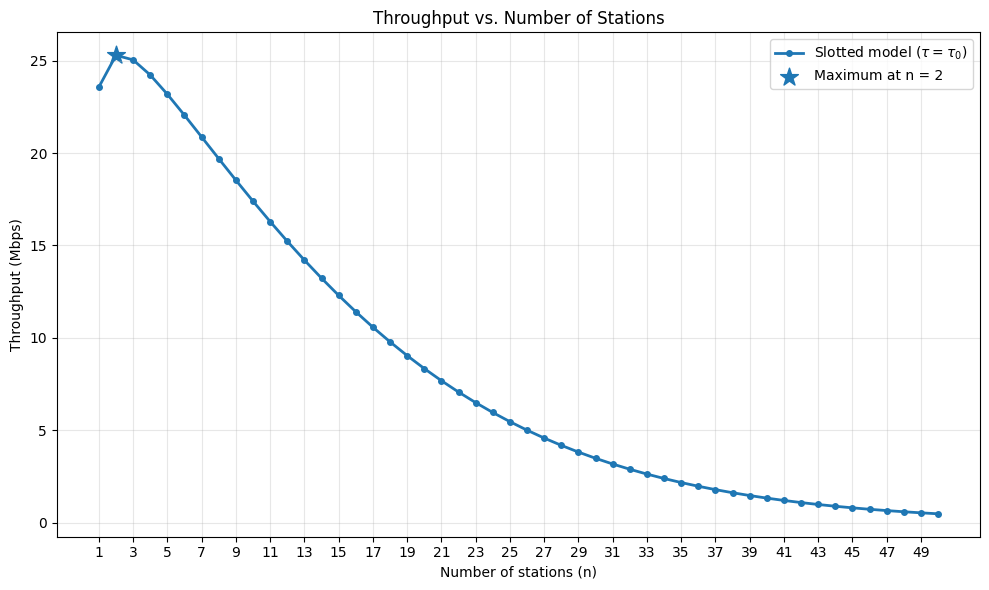

In [14]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt

# Load group parameters
with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)

L = P["L"]
R = P["R"]

# MAC frame size includes the 31-byte protocol overhead
B = L + 31

# Calculate DATA transmission time using the 802.11a OFDM formula
N_DBPS = 4 * R
N_SYM = np.ceil((16 + 8 * B + 6) / N_DBPS)
T_DATA = 20e-6 + 4e-6 * N_SYM

# Define MAC timing parameters
CW_min = 15
sigma = 9e-6
DIFS = 34e-6
SIFS = 16e-6
T_ACK = 28e-6

# Calculate the fixed transmission probability
tau_0 = 2 / (CW_min + 2)

# Calculate successful and collision slot durations
T_s = DIFS + T_DATA + SIFS + T_ACK
T_c = DIFS + T_DATA

# Evaluate the model for 1 to 50 stations
n_values = np.arange(1, 51)

# Calculate the probability of each slot outcome
P_idle = (1 - tau_0) ** n_values
P_s = n_values * tau_0 * (1 - tau_0) ** (n_values - 1)
P_c = 1 - P_idle - P_s

# Calculate network throughput
S = (P_s * 8 * L) / (
    P_idle * sigma +
    P_s * T_s +
    P_c * T_c
)

# Convert throughput from bps to Mbps
S_Mbps = S / 1e6

# Calculate the single-station analytical throughput
k = CW_min / 2
S1 = (8 * L) / (
    DIFS + k * sigma + T_DATA + SIFS + T_ACK
)

# Verify that the model matches S1 when n = 1
assert np.isclose(S[0], S1, rtol=1e-10), (
    "The n=1 throughput does not match the analytical S1 value."
)

# Find the station count that gives maximum throughput
max_index = np.argmax(S_Mbps)
max_n = n_values[max_index]
max_S = S_Mbps[max_index]

# Print the calculated parameters and results
print(f"L = {L} Bytes")
print(f"R = {R} Mbps")
print(f"DATA transmission time = {T_DATA * 1e6:.2f} us")
print(f"tau_0 = {tau_0:.6f}")
print(f"T_s = {T_s * 1e6:.2f} us")
print(f"T_c = {T_c * 1e6:.2f} us")

print(f"\nS1 from section 1-3 = {S1 / 1e6:.4f} Mbps")
print(f"S(1) from slotted model = {S_Mbps[0]:.4f} Mbps")
print(f"Maximum throughput = {max_S:.4f} Mbps")
print(f"Maximum throughput occurs at n = {max_n}")

# Plot throughput versus the number of stations
plt.figure(figsize=(10, 6))

plt.plot(
    n_values,
    S_Mbps,
    marker="o",
    markersize=4,
    linewidth=2,
    label=r"Slotted model ($\tau = \tau_0$)"
)

plt.scatter(
    max_n,
    max_S,
    marker="*",
    s=180,
    label=f"Maximum at n = {max_n}"
)

plt.xlabel("Number of stations (n)")
plt.ylabel("Throughput (Mbps)")
plt.title("Throughput vs. Number of Stations")
plt.xticks(np.arange(1, 51, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 1-3  Model versus simulator

## 1-4  Hidden terminal and RTS/CTS